In [1]:
import h5py
import numpy as np
from scipy.signal import wiener
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import auroral_processing
from auroral_processing.utils.norm import compute_norm_from_hdf
import importlib

In [28]:
importlib.reload(auroral_processing)

<module 'auroral_processing' from '/Users/michaellavender/Developer/AuroralProcessing/auroral_processing/__init__.py'>

In [4]:
ls ../data

2013-03-27-CamSer7196_015400-015600-p.mp4
2013-03-27-CamSer7196_015400-015600-up.mp4
2013-03-27-CamSer7196_015400-015600.h5


In [2]:
hdf_fn = Path('../data/2013-03-27-CamSer7196_015400-015600.h5').resolve()

In [3]:
f = h5py.File(hdf_fn, 'r')
imgs = f['rawimg']

In [4]:
norm = compute_norm_from_hdf(hdf_fn, 1)

computing norm:   0%|          | 0/3 [00:00<?, ?chunk/s]

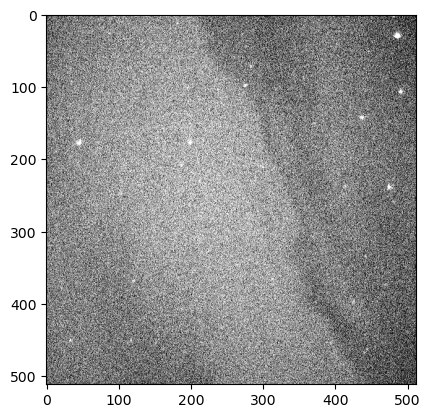

In [5]:
img = imgs[100]
plt.imshow(img, 'gray', norm=norm)

np.float64(139904.94550630997)

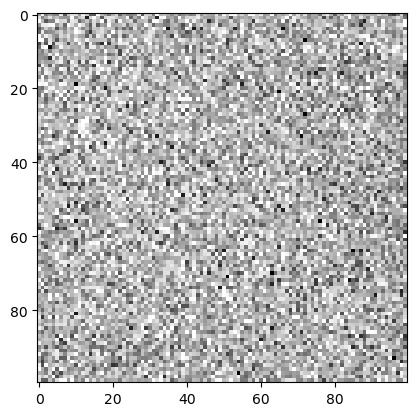

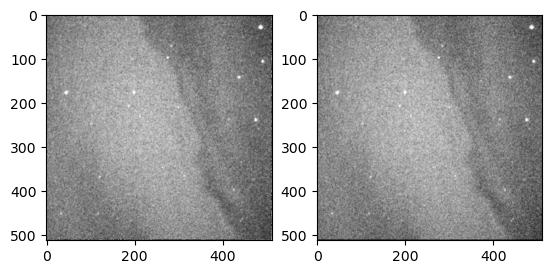

In [43]:
sample = img[200:300, 200:300]
# plt.imshow(sample, 'gray', norm=norm)
var = np.var(sample)
filtered1 = wiener(img)
filtered2 = wiener(img, noise=var)
fig, axes = plt.subplots(1, 2)
axes[0].imshow(filtered1, 'gray', norm=norm)
axes[1].imshow(filtered2, 'gray', norm=norm)